# COU 07506 — Week 4: z-Transform Laboratory, Poles, Zeros and Stability

**Student:** Zaid Yaseer Yussuf &nbsp;|&nbsp; **Registration number:** 240242479517 &nbsp;|&nbsp;
**Class:** BEng24COE &nbsp;|&nbsp; **Date:** 26 November 2026 &nbsp;|&nbsp;
**Submission:** Individual laboratory work.

## Pre-lab preparation

**Reading.** Handout §2.2–§2.4, Listing 2.1 and Examples 2.2–2.5.

**(a)** For 1 − 0.9z⁻¹ + 0.81z⁻², z² − 0.9z + 0.81 = 0 gives
z = 0.45 ± j0.779 = 0.9e^{±jπ/3}. Since |p| = 0.9 < 1, the causal system is stable.

**(b)** Partial fractions:

X(z) = 1/[(1 − 0.5z⁻¹)(1 − 0.25z⁻¹)]
     = 2/(1 − 0.5z⁻¹) − 1/(1 − 0.25z⁻¹),

so x(n) = 2(0.5)ⁿ − (0.25)ⁿ for n ≥ 0.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
FIGDIR = ROOT / "report" / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)
DATA = ROOT / "data"
REPORT = ROOT / "report"
REPORT.mkdir(parents=True, exist_ok=True)
print("Repository root:", ROOT)

Repository root: C:\Users\zayee\Documents\Default Project\COU07506-labs


In [2]:
def zplane(b, a, ax=None, extra_poles_at_origin=0):
    """Pole-zero plot with the unit circle (Task 4.1)."""
    z, p, k = signal.tf2zpk(b, a)
    p = np.concatenate([p, np.zeros(extra_poles_at_origin)])
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8, label="unit circle")
    if len(z):
        ax.plot(z.real, z.imag, "o", mfc="none", ms=8, color="C0", label="zeros")
    if len(p):
        ax.plot(p.real, p.imag, "x", ms=8, mew=2, color="C1", label="poles")
    ax.set_aspect("equal")
    ax.set_xlabel("Re(z)")
    ax.set_ylabel("Im(z)")
    ax.legend(loc="upper right", fontsize=8)
    return z, p

def inverse_check(b, a, N=10):
    r, p, k = signal.residuez(b, a)
    n = np.arange(N)
    h_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real
    imp = np.zeros(N); imp[0] = 1
    h_lf = signal.lfilter(b, a, imp)
    return r, p, h_pf, h_lf, bool(np.allclose(h_pf, h_lf))

def pole_pair(radius, theta=np.pi/4, N=40):
    a = [1, -2*radius*np.cos(theta), radius**2]
    imp = np.zeros(N); imp[0] = 1
    h = signal.lfilter([1], a, imp)
    w, H = signal.freqz([1], a, worN=4001)
    mag = np.abs(H)
    peak_db = float(20*np.log10(np.max(mag)))
    if radius < 1:
        above = w[mag >= np.max(mag)/np.sqrt(2)]
        bw_pi = float((above.max() - above.min()) / np.pi)
    else:
        bw_pi = float("nan")
    return {"a": a, "h": h, "w": w, "H": H, "peak_db": peak_db,
            "bw_pi": bw_pi, "h_last": float(np.max(np.abs(h[-10:])))}

SYS4 = {"H1": ([1], [1, -1.6, 0.89]),
        "H2": ([1, 1], [1, -2.5, 1]),
        "H3": ([1], [1, 0.5, -0.5]),
        "H4": ([1, 0, 0, 0, -1], [1])}

def classify(b, a, N=200):
    z, p = zplane(b, a)
    imp = np.zeros(N); imp[0] = 1
    h = signal.lfilter(b, a, imp)
    rmax = float(np.max(np.abs(p))) if len(p) else 0.0
    return {"z": z, "p": p, "h": h, "rmax": rmax,
            "tail": float(np.max(np.abs(h[150:]))),
            "abssum": float(np.sum(np.abs(h)))}

## Task 4.1 — A pole-zero plotting function

Apply `zplane` to H(z) = (1 + z⁻¹)/(1 − 0.75z⁻¹ + 0.125z⁻²) and plot the
magnitude response.

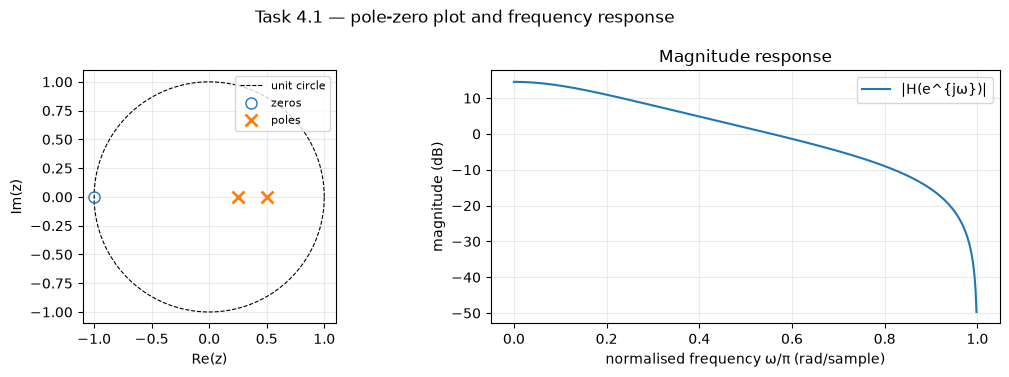

zeros: [-1.]
poles: [0.5  0.25]
all poles inside unit circle: True
gain at ω=0 (dB): 14.54
gain at ω=pi (dB): -49.7


In [3]:
b41, a41 = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
z41, p41 = zplane(b41, a41, ax1)
w41, H41 = signal.freqz(b41, a41, worN=512)
ax2.plot(w41/np.pi, 20*np.log10(np.abs(H41)), label="|H(e^{jω})|")
ax2.set_xlabel("normalised frequency ω/π (rad/sample)")
ax2.set_ylabel("magnitude (dB)")
ax2.set_title("Magnitude response")
ax2.legend()
fig.suptitle("Task 4.1 — pole-zero plot and frequency response")
fig.tight_layout()
fig.savefig(FIGDIR / "week04_task4_1.png", dpi=160, bbox_inches="tight")
plt.show()
print("zeros:", np.round(z41, 6))
print("poles:", np.round(p41, 6))
print("all poles inside unit circle:", bool(np.all(np.abs(p41) < 1)))
print("gain at ω=0 (dB):", round(float(20*np.log10(abs(H41[0]))), 2))
print("gain at ω=pi (dB):", round(float(20*np.log10(abs(H41[-1]))), 2))

## Task 4.2 — Inverse z-transform with `residuez`

Compare the partial-fraction reconstruction Σrᵢpᵢⁿ with `lfilter` for b = [1] and
for b = [1, 1].

b =

 [1]  residues = [-1.  2.]  poles = [0.25 0.5 ]  matches: True
b = [1, 1]  residues = [-5.  6.]  poles = [0.25 0.5 ]  matches: True


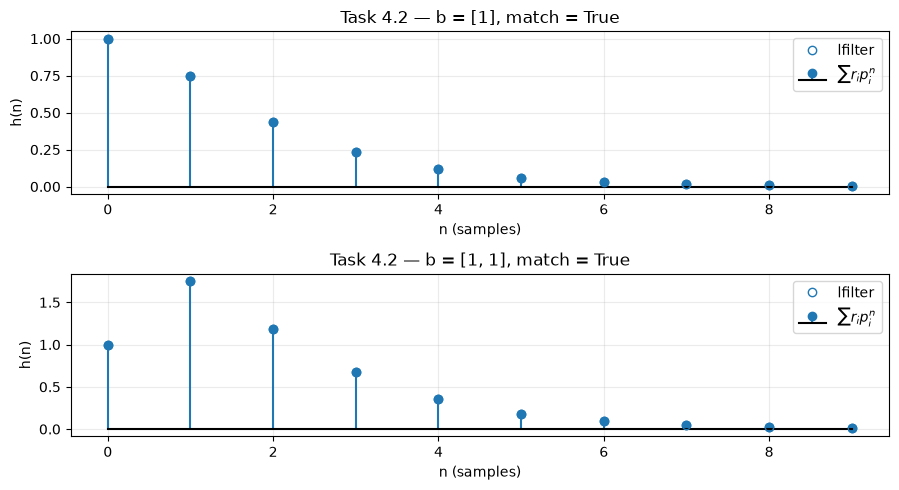

,b,residues,poles,matches_lfilter
0,[1],"[-1.0, 2.0]","[0.25, 0.5]",True
1,"[1, 1]","[-5.0, 6.0]","[0.25, 0.5]",True


In [4]:
residue_rows = []
fig, axes = plt.subplots(2, 1, figsize=(9, 5))
for ax, b_now in zip(axes, [[1], [1, 1]]):
    r, p, h_pf, h_lf, ok = inverse_check(b_now, a41, N=10)
    residue_rows.append({"b": str(b_now), "residues": [round(float(v), 4) for v in r],
                         "poles": [round(float(v), 4) for v in p], "matches_lfilter": ok})
    n_now = np.arange(10)
    ax.stem(n_now, h_pf, basefmt="k-", label=r"$\sum r_i p_i^n$")
    ax.plot(n_now, h_lf, "o", mfc="none", label="lfilter")
    ax.set_title(f"Task 4.2 — b = {b_now}, match = {ok}")
    ax.set_xlabel("n (samples)")
    ax.set_ylabel("h(n)")
    ax.legend()
    print("b =", b_now, " residues =", np.round(r, 4), " poles =", np.round(p, 4),
          " matches:", ok)
fig.tight_layout()
fig.savefig(FIGDIR / "week04_task4_2.png", dpi=160, bbox_inches="tight")
plt.show()
display(pd.DataFrame(residue_rows))

For b = [1] the residues are −1 at p = 0.25 and +2 at p = 0.5, giving
x(n) = 2(0.5)ⁿ − (0.25)ⁿ. For b = [1, 1] they are −5 and +6, confirming
h(n) = 6(0.5)ⁿ − 5(0.25)ⁿ from Task 3.5.

## Task 4.3 — Pole position and the impulse response

For poles at r·e^{±jπ/4}, A(z) = 1 − 2r cos(π/4)z⁻¹ + r²z⁻². Plot h(n) and |H(e^{jω})|
for r = 0.5, 0.8, 0.95, 1.0 and 1.05.

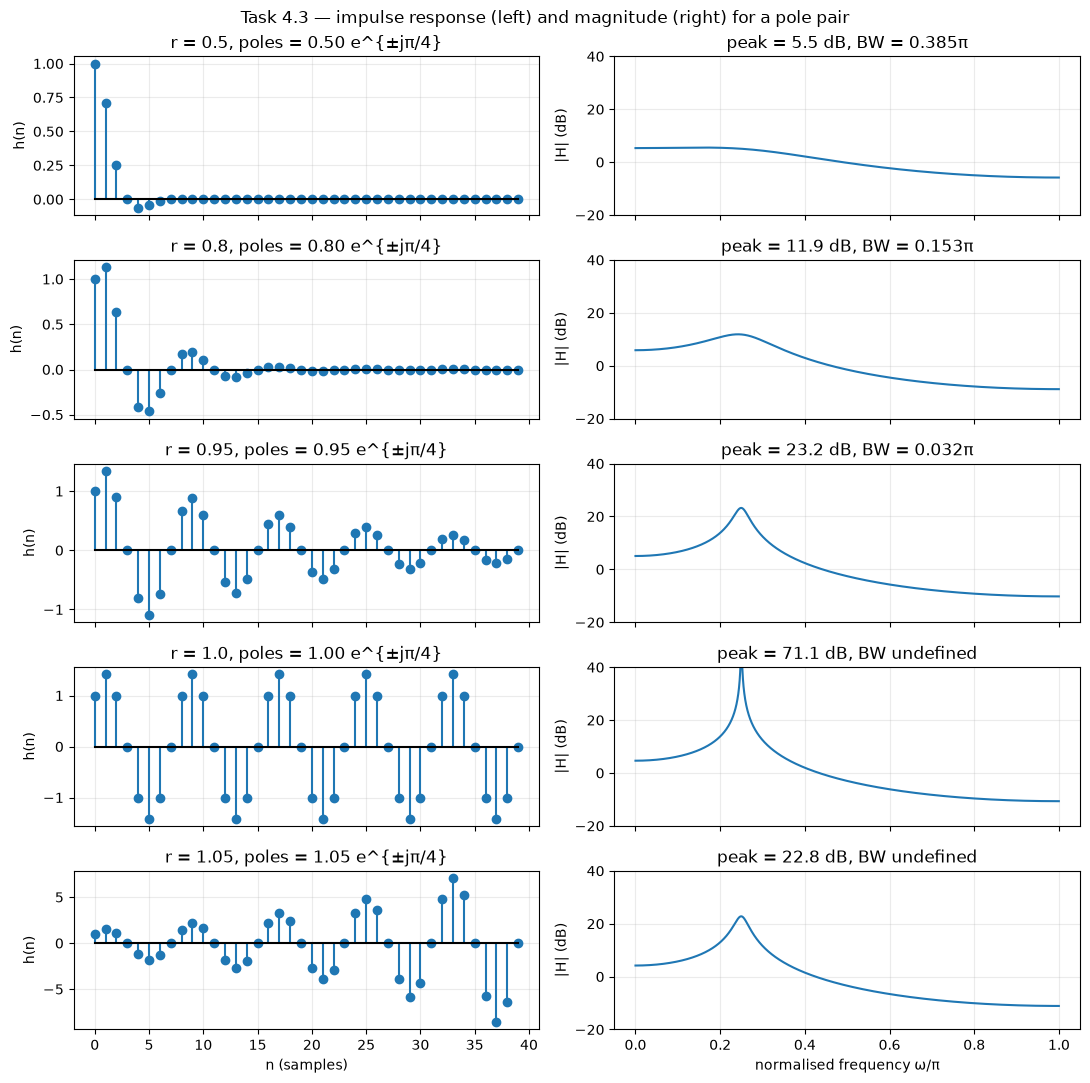

,r,peak_dB,bw_over_pi,max_h_last10,stable
0,0.50,5.51,0.385,0.0000,True
1,0.80,11.88,0.153,0.0012,True
2,0.95,23.23,0.032,0.2603,True
3,1.00,71.13,NaN,1.4142,False
4,1.05,22.80,NaN,8.6004,False


In [5]:
radii = [0.5, 0.8, 0.95, 1.0, 1.05]
pole_rows = []
fig, axes = plt.subplots(5, 2, figsize=(11, 11), sharex="col")
for row, radius in enumerate(radii):
    d = pole_pair(radius)
    h_now = d["h"]
    axes[row, 0].stem(np.arange(len(h_now)), h_now, basefmt="k-")
    axes[row, 0].set_title(f"r = {radius}, poles = {radius:.2f} e^{{±jπ/4}}")
    axes[row, 0].set_ylabel("h(n)")
    mag_db = 20*np.log10(np.maximum(np.abs(d["H"]), 1e-12))
    axes[row, 1].plot(d["w"]/np.pi, mag_db)
    axes[row, 1].set_ylim(-20, 40)
    axes[row, 1].set_ylabel("|H| (dB)")
    axes[row, 1].set_title(f"peak = {d['peak_db']:.1f} dB, "
                           + (f"BW = {d['bw_pi']:.3f}π" if radius < 1 else "BW undefined"))
    pole_rows.append({"r": radius, "peak_dB": round(d["peak_db"], 2),
                      "bw_over_pi": (round(d["bw_pi"], 3) if radius < 1 else None),
                      "max_h_last10": round(d["h_last"], 4),
                      "stable": bool(radius < 1)})
axes[-1, 0].set_xlabel("n (samples)")
axes[-1, 1].set_xlabel("normalised frequency ω/π")
fig.suptitle("Task 4.3 — impulse response (left) and magnitude (right) for a pole pair")
fig.tight_layout()
fig.savefig(FIGDIR / "week04_task4_3.png", dpi=160, bbox_inches="tight")
plt.show()
display(pd.DataFrame(pole_rows))

As r → 1 the resonance at ω = π/4 becomes taller and narrower and h(n) decays
more slowly. The −3 dB bandwidth follows ≈ 2(1 − r) rad/sample. At r = 1 the
response is a sustained sinusoid; at r = 1.05 it grows, so both are not BIBO stable.

## Task 4.4 — Stability of given systems

Classify H1–H4 from pole positions and verify with h(n) over 200 samples.

H1 max|p| = 0.9434 tail = 0.000236 sum|h| = 21.8
H2 max|p| = 2.0 tail = 1.61e+60 sum|h| = 3.21e+60
H3 max|p| = 1.0 tail = 0.667 sum|h| = 134
H4 max|p| = 0.0 tail = 0 sum|h| = 2


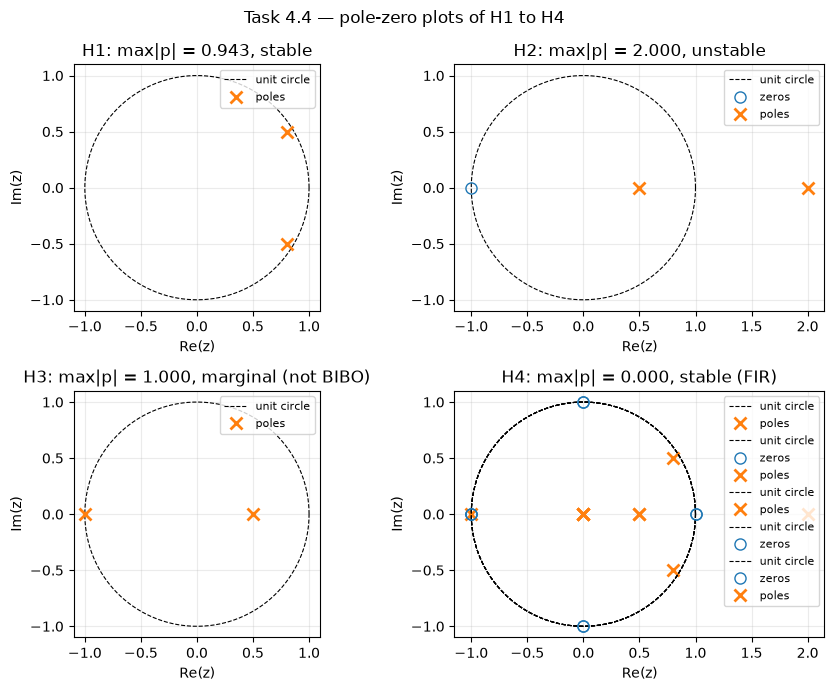

,system,poles,max_pole_radius,max_h_n_ge_150,sum_abs_h,classification
0,H1,"0.800+0.500j, 0.800-0.500j",0.943,0.000236,21.8,stable
1,H2,"2.000+0.000j, 0.500+0.000j",2.000,1.61e+60,3.21e+60,unstable
2,H3,"-1.000+0.000j, 0.500+0.000j",1.000,0.667,134,marginal (not BIBO)
3,H4,"0.000+0.000j, 0.000+0.000j, 0.000+0.000j, 0.00...",0.000,0,2,stable (FIR)


In [6]:
system_rows = []
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
labels = {"H1": "stable", "H2": "unstable", "H3": "marginal (not BIBO)", "H4": "stable (FIR)"}
for ax, (name, (b_now, a_now)) in zip(axes.ravel(), SYS4.items()):
    d = classify(b_now, a_now)
    extra = 4 if name == "H4" else 0
    z, p = zplane(b_now, a_now, ax=ax, extra_poles_at_origin=extra)
    ax.set_title(f"{name}: max|p| = {d['rmax']:.3f}, {labels[name]}")
    system_rows.append({"system": name,
                        "poles": ", ".join(f"{v.real:.3f}{v.imag:+.3f}j" for v in p),
                        "max_pole_radius": round(d["rmax"], 3),
                        "max_h_n_ge_150": f"{d['tail']:.3g}",
                        "sum_abs_h": f"{d['abssum']:.3g}",
                        "classification": labels[name]})
    print(name, "max|p| =", round(d["rmax"], 4),
          "tail =", f"{d['tail']:.3g}", "sum|h| =", f"{d['abssum']:.3g}")
fig.suptitle("Task 4.4 — pole-zero plots of H1 to H4")
fig.tight_layout()
fig.savefig(FIGDIR / "week04_task4_4.png", dpi=160, bbox_inches="tight")
plt.show()
display(pd.DataFrame(system_rows))

H1 is stable (|p| = 0.943); H2 has a pole at z = 2 and grows without bound; H3
has a pole at z = −1 on the unit circle, so h(n) oscillates without decaying and
Σ|h(n)| diverges; H4 = 1 − z⁻⁴ is FIR with all poles at the origin and is stable.

## Task 4.5 — Design a resonator

Poles at r·e^{±jθ} with r = 0.97 and θ = 2π·1000/8000 = π/4; zeros at z = ±1
give B(z) = 1 − z⁻². The numerator is scaled for unit gain at the peak and the
filter is applied to white noise.

peak frequency: 1000 Hz
-3 dB bandwidth: 76.7 Hz (approximation 2(1-r)fs/2pi = 76.4 Hz)
gain at 0 Hz: 0; gain at fs/2: 6.84e-06


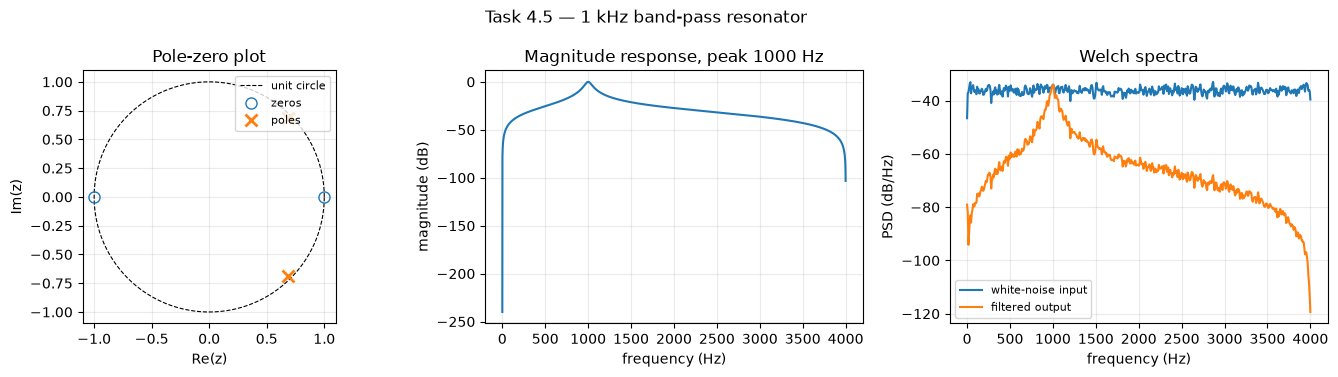

In [7]:
fs_res, f0_res, r_res = 8000, 1000, 0.97
theta = 2*np.pi*f0_res/fs_res
a_res = np.array([1, -2*r_res*np.cos(theta), r_res**2])
b_res = np.array([1.0, 0, -1.0])
w_res, H_res = signal.freqz(b_res, a_res, worN=8192, fs=fs_res)
b_res = b_res / np.max(np.abs(H_res))
w_res, H_res = signal.freqz(b_res, a_res, worN=8192, fs=fs_res)
mag_res = np.abs(H_res)
f_peak = float(w_res[np.argmax(mag_res)])
above = w_res[mag_res >= 1/np.sqrt(2)]
bw_hz = float(above.max() - above.min())
rng = np.random.default_rng(0)
x_res = rng.standard_normal(8000)
y_res = signal.lfilter(b_res, a_res, x_res)
f_w, Pxx = signal.welch(x_res, fs=fs_res, nperseg=1024)
f_w2, Pyy = signal.welch(y_res, fs=fs_res, nperseg=1024)
approx_bw = 2*(1-r_res)*fs_res/(2*np.pi)
print(f"peak frequency: {f_peak:.0f} Hz")
print(f"-3 dB bandwidth: {bw_hz:.1f} Hz (approximation 2(1-r)fs/2pi = {approx_bw:.1f} Hz)")
print(f"gain at 0 Hz: {abs(H_res[0]):.3g}; gain at fs/2: {abs(H_res[-1]):.3g}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
zplane(b_res, a_res, ax=axes[0])
axes[0].set_title("Pole-zero plot")
axes[1].plot(w_res, 20*np.log10(np.maximum(mag_res, 1e-12)))
axes[1].set_title(f"Magnitude response, peak {f_peak:.0f} Hz")
axes[1].set_xlabel("frequency (Hz)")
axes[1].set_ylabel("magnitude (dB)")
axes[2].plot(f_w, 10*np.log10(Pxx + 1e-12), label="white-noise input")
axes[2].plot(f_w2, 10*np.log10(Pyy + 1e-12), label="filtered output")
axes[2].set_title("Welch spectra")
axes[2].set_xlabel("frequency (Hz)")
axes[2].set_ylabel("PSD (dB/Hz)")
axes[2].legend(fontsize=8)
fig.suptitle("Task 4.5 — 1 kHz band-pass resonator")
fig.tight_layout()
fig.savefig(FIGDIR / "week04_task4_5.png", dpi=160, bbox_inches="tight")
plt.show()

# Listening check (uncomment in a notebook):
# display(Audio(y_res/np.max(np.abs(y_res)), rate=fs_res))

## Analysis questions

1. **Effect of r.** The −3 dB bandwidth of the resonance is ≈ 2(1 − r)
   rad/sample: raising r from 0.8 to 0.95 narrows the peak from about 0.153π to
   0.032π and lengthens h(n).
2. **Pole on the unit circle.** h(n) neither decays nor grows. A complex pair at
   e^{±jθ} gives a sustained sinusoid h(n) = sin((n+1)θ)/sinθ; a pole at ±1 gives
   a constant or alternating sequence. Σ|h(n)| diverges, so the system is not BIBO stable.
3. **Zeros at z = ±1.** A zero at z = 1 blocks DC (ω = 0) and a zero at z = −1
   blocks fs/2 (ω = π). With the poles providing gain at 1 kHz, the response is a
   band-pass shape.
4. **Stability triangle.** For A(z) = 1 + a₁z⁻¹ + a₂z⁻², stability requires
   |a₂| < 1 and |a₁| < 1 + a₂. (a) a₁ = −1.6, a₂ = 0.89: 1.6 < 1.89, stable.
   (b) a₁ = −2.5, a₂ = 1: |a₂| = 1, unstable. (c) a₁ = 0.5, a₂ = −0.5:
   |a₁| = 1 + a₂ = 0.5, on the boundary, so a pole lies at z = −1 (marginal).

In [8]:
results_week04 = {
    "week": 4,
    "task41": {"zeros": [f"{v.real:.4f}{v.imag:+.4f}j" for v in z41],
               "poles": [f"{v.real:.4f}{v.imag:+.4f}j" for v in p41],
               "stable": bool(np.all(np.abs(p41) < 1)),
               "gain_0_dB": round(float(20*np.log10(abs(H41[0]))), 2),
               "gain_pi_dB": round(float(20*np.log10(abs(H41[-1]))), 2)},
    "residues": residue_rows,
    "pole_pair": pole_rows,
    "systems": system_rows,
    "resonator": {"peak_Hz": round(f_peak, 1),
                  "bw_Hz": round(bw_hz, 1),
                  "bw_approx_Hz": round(approx_bw, 1),
                  "gain_0": float(abs(H_res[0])),
                  "gain_nyquist": float(abs(H_res[-1])),
                  "b": [float(v) for v in b_res],
                  "a": [float(v) for v in a_res]},
}
(REPORT / "results_week04.json").write_text(json.dumps(results_week04, indent=2))
print(json.dumps(results_week04, indent=2))

{
  "week": 4,
  "task41": {
    "zeros": [
      "-1.0000+0.0000j"
    ],
    "poles": [
      "0.5000+0.0000j",
      "0.2500+0.0000j"
    ],
    "stable": true,
    "gain_0_dB": 14.54,
    "gain_pi_dB": -49.7
  },
  "residues": [
    {
      "b": "[1]",
      "residues": [
        -1.0,
        2.0
      ],
      "poles": [
        0.25,
        0.5
      ],
      "matches_lfilter": true
    },
    {
      "b": "[1, 1]",
      "residues": [
        -5.0,
        6.0
      ],
      "poles": [
        0.25,
        0.5
      ],
      "matches_lfilter": true
    }
  ],
  "pole_pair": [
    {
      "r": 0.5,
      "peak_dB": 5.51,
      "bw_over_pi": 0.385,
      "max_h_last10": 0.0,
      "stable": true
    },
    {
      "r": 0.8,
      "peak_dB": 11.88,
      "bw_over_pi": 0.153,
      "max_h_last10": 0.0012,
      "stable": true
    },
    {
      "r": 0.95,
      "peak_dB": 23.23,
      "bw_over_pi": 0.032,
      "max_h_last10": 0.2603,
      "stable": true
    },
    {
      "r": 

## AI-use statement

**Tool:** OpenCode (model Big Pickle). **Used for:** drafting the Python code and
written answers in this notebook. **Verification:** the notebook was restarted and
run from top to bottom; residues were compared with the hand partial-fraction
expansion, pole positions with hand root calculations, stability with the
stability triangle, and the resonator peak/bandwidth with 2(1 − r)fs/2π. I can
explain every line of code.